# Lab 8.3: Backgrounds, Correlation and Estimators

Synthetic data only, so you know the truth. Run the cells in order. Cells marked **EDIT** invite you to change one number and run again.

1. Shapley values from scratch, checked against a library.
2. Correlated features: interventional versus observational values.
3. Estimators: how fast do sampled values approach the exact ones, and what does a library default do?
4. SHAP interaction values.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from itertools import combinations
from math import factorial
import numpy as np, matplotlib.pyplot as plt, shap, sklearn
from sklearn.ensemble import GradientBoostingRegressor
print("numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| shap", shap.__version__)

numpy 2.2.6 | scikit-learn 1.7.2 | shap 0.49.1


## 1. Shapley values from scratch

A model with 12 independent standard normal features. The true function is $y = 2x_1 + x_2 x_3 + 0.5x_4 + 0.2(x_5 + \dots + x_{12})$ plus noise. We fit a gradient-boosted regressor, then compute exact interventional Shapley values for one case against a background of 50 rows by listing all $2^{12} = 4{,}096$ coalitions.

In [2]:
rng = np.random.default_rng(0)
M = 12
X = rng.normal(size=(4000, M))
y = 2 * X[:, 0] + X[:, 1] * X[:, 2] + 0.5 * X[:, 3] + 0.2 * X[:, 4:].sum(1) + rng.normal(0, 0.3, 4000)
model = GradientBoostingRegressor(n_estimators=400, max_depth=4, random_state=0).fit(X, y)
bg = X[rng.choice(4000, 50, replace=False)]
x = np.array([1.5, 1.0, -1.0, 1.0] + [0.5] * 8)

def value(S, x=x, bg=bg):
    Z = bg.copy(); Z[:, list(S)] = x[list(S)]
    return model.predict(Z).mean()

V = {}
for k in range(M + 1):
    for S in combinations(range(M), k):
        V[frozenset(S)] = value(S)
phi = np.zeros(M)
for i in range(M):
    for S, vS in V.items():
        if i not in S:
            phi[i] += factorial(len(S)) * factorial(M - len(S) - 1) / factorial(M) * (V[S | {i}] - vS)
lib = shap.TreeExplainer(model, data=bg, feature_perturbation="interventional").shap_values(x[None])[0]
print("from scratch:", phi.round(3))
print("shap library:", lib.round(3))
print("max difference:", float(np.abs(phi - lib).max()), "| sum:", round(phi.sum(), 3), "| gap:", round(model.predict(x[None])[0] - V[frozenset()], 3))

from scratch: [ 3.207 -0.431 -0.361  0.342  0.084  0.117  0.063  0.086  0.142  0.091
 -0.013  0.022]
shap library: [ 3.207 -0.431 -0.361  0.342  0.084  0.117  0.063  0.086  0.142  0.091
 -0.013  0.022]
max difference: 2.396752663003099e-08 | sum: 3.35 | gap: 3.35


**Checkpoint 1:** the two rows agree to better than $10^{-7}$, and the values add up to the gap of 3.350. $x_1$ gets 3.207; $x_2$ and $x_3$ get -0.431 and -0.361, mostly their shares of the interaction (for this case $x_2 x_3 = 1.0 \times -1.0 = -1$, against a background where the product averages about 0).

## 2. Correlated features: interventional versus observational

The model is $f = x_1 + x_3$ and never reads $x_2$, but $x_2$ is correlated with $x_1$. We explain the case $x = (1, 1, 1)$ two ways, by Monte Carlo:

- **interventional:** missing features are drawn from their marginal distribution (independently of the present ones);
- **observational:** missing features are drawn from their distribution *given* the present ones (here exact, because the data are Gaussian).

In [3]:
def shapley3(v):
    P = [0, 1, 2]; out = np.zeros(3)
    for i in P:
        for k in range(3):
            for S in combinations([p for p in P if p != i], k):
                out[i] += factorial(k) * factorial(2 - k) / 6 * (v(set(S) | {i}) - v(set(S)))
    return out

def explain(rho, n=40000, seed=0):
    g = np.random.default_rng(seed)
    f = lambda Z: Z[:, 0] + Z[:, 2]
    x = np.array([1.0, 1.0, 1.0])
    def v_int(S):
        Z = g.normal(size=(n, 3)); Z[:, 1] = rho * Z[:, 0] + np.sqrt(1 - rho**2) * Z[:, 1]
        for j in S: Z[:, j] = x[j]
        return f(Z).mean()
    def v_obs(S):
        Z = g.normal(size=(n, 3))
        if 0 in S and 1 not in S:   Z[:, 1] = rho * x[0] + np.sqrt(1 - rho**2) * Z[:, 1]
        elif 1 in S and 0 not in S: Z[:, 0] = rho * x[1] + np.sqrt(1 - rho**2) * Z[:, 0]
        elif 0 not in S and 1 not in S: Z[:, 1] = rho * Z[:, 0] + np.sqrt(1 - rho**2) * Z[:, 1]
        for j in S: Z[:, j] = x[j]
        return f(Z).mean()
    return shapley3(v_int), shapley3(v_obs)

rho = 0.9   # EDIT: try 0.0, 0.5, 0.95
si, so = explain(rho)
print(f"rho = {rho}: interventional {si.round(3)} | observational {so.round(3)} | theory for x2, observational: {rho / 2:.3f}")

rho = 0.9: interventional [9.920e-01 1.000e-03 1.001e+00] | observational [0.55  0.45  1.001] | theory for x2, observational: 0.450


**Checkpoint 2:** at $\rho = 0.9$, interventional values are about (1, 0, 1); observational values are about (0.55, 0.45, 1). Monte Carlo noise moves the third decimal.

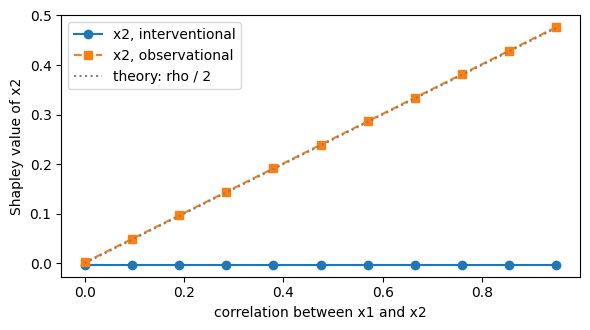

In [4]:
rhos = np.linspace(0, 0.95, 11)
res = np.array([np.concatenate(explain(r, n=20000)) for r in rhos])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(rhos, res[:, 1], "o-", label="x2, interventional")
ax.plot(rhos, res[:, 4], "s--", label="x2, observational")
ax.plot(rhos, rhos / 2, ":", color="gray", label="theory: rho / 2")
ax.set_xlabel("correlation between x1 and x2"); ax.set_ylabel("Shapley value of x2"); ax.legend(); plt.tight_layout(); plt.show()

**Checkpoint 3:** the interventional line stays at 0; the observational line follows $\rho/2$. Hand in this plot.

## 3. Estimators against the exact values

Back to the 12-feature model of Section 1, where we know the exact values. We compare three estimators at several budgets (number of coalitions evaluated), three runs each:

- our own **permutation sampling** (random orders, marginal contributions along each order);
- **Kernel SHAP** from the shap library with its default setting, which in shap 0.49.1 keeps only 10 features (`l1_reg="num_features(10)"`);
- **Kernel SHAP** with that feature selection switched off (`l1_reg=False`).

In [5]:
def perm_sampling(budget, seed):
    g = np.random.default_rng(seed); est = np.zeros(M); count = 0; used = 0
    while used + M + 1 <= budget:
        order = g.permutation(M); S = []; prev = value([])
        for i in order:
            S.append(i); cur = value(S); est[i] += cur - prev; prev = cur
        used += M + 1; count += 1
    return est / max(count, 1)

err = lambda e: np.abs(e - phi).sum() / np.abs(phi).sum()
budgets = [64, 128, 256, 512, 1024]   # EDIT: add 2048 if you have time
f = lambda Z: model.predict(Z)
rows = []
for b in budgets:
    ep = np.mean([err(perm_sampling(b, s)) for s in range(3)])
    K = shap.KernelExplainer(f, bg)
    ed, ef = [], []
    for s in range(3):
        np.random.seed(s); ed.append(err(K.shap_values(x[None], nsamples=b, silent=True)[0]))
        np.random.seed(s); ef.append(err(K.shap_values(x[None], nsamples=b, l1_reg=False, silent=True)[0]))
    rows.append((b, ep, np.mean(ed), np.mean(ef)))
    print(f"budget {b:5d}: permutation {ep:.3f} | Kernel default {np.mean(ed):.3f} | Kernel no selection {np.mean(ef):.3f}")

budget    64: permutation 0.095 | Kernel default 0.067 | Kernel no selection 0.063


budget   128: permutation 0.059 | Kernel default 0.035 | Kernel no selection 0.030


budget   256: permutation 0.028 | Kernel default 0.028 | Kernel no selection 0.024


budget   512: permutation 0.031 | Kernel default 0.019 | Kernel no selection 0.015


budget  1024: permutation 0.022 | Kernel default 0.016 | Kernel no selection 0.011


**Checkpoint 4:** at 1,024 coalitions the errors are about 0.02 (permutation), 0.016 (Kernel default) and 0.011 (Kernel without selection). The default keeps 10 of 12 features; the two it drops are small here, so the cost is small. On the 19-feature credit model of Chapter 8, the same default left an error of about 18 percent that more samples did not reduce.

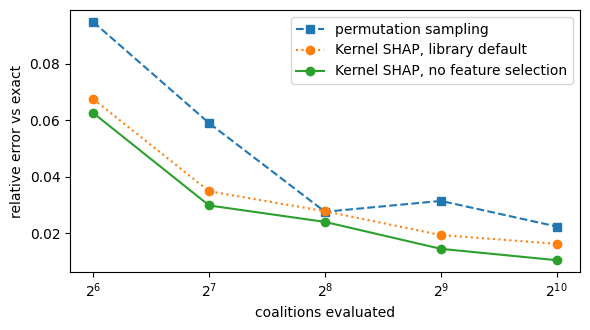

In [6]:
R = np.array(rows)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(R[:, 0], R[:, 1], "s--", label="permutation sampling")
ax.plot(R[:, 0], R[:, 2], "o:", label="Kernel SHAP, library default")
ax.plot(R[:, 0], R[:, 3], "o-", label="Kernel SHAP, no feature selection")
ax.set_xscale("log", base=2); ax.set_xlabel("coalitions evaluated"); ax.set_ylabel("relative error vs exact")
ax.legend(); plt.tight_layout(); plt.show()

## 4. SHAP interaction values

The true function contains one interaction, $x_2 x_3$. TreeSHAP's interaction values split each prediction into main effects (diagonal) and pairwise interactions (off-diagonal). They use the path-dependent version, which needs no background.

largest off-diagonal pair: (2, 3) value (each half): -0.379
row sums equal the path-dependent SHAP values: True


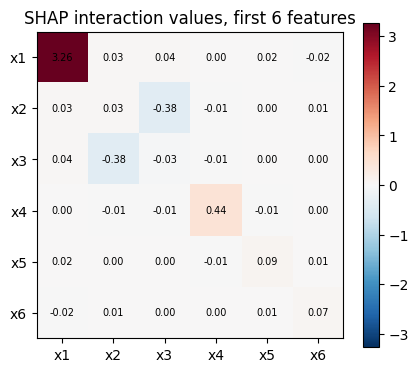

In [7]:
ex = shap.TreeExplainer(model)
I = ex.shap_interaction_values(x[None])[0]
off = I.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(np.abs(off).argmax(), off.shape)
print("largest off-diagonal pair:", (int(i) + 1, int(j) + 1), "value (each half):", round(off[i, j], 3))
print("row sums equal the path-dependent SHAP values:", np.allclose(I.sum(1), ex.shap_values(x[None])[0], atol=1e-4))
fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(I[:6, :6], cmap="RdBu_r", vmin=-np.abs(I).max(), vmax=np.abs(I).max())
ax.set_xticks(range(6)); ax.set_xticklabels([f"x{k+1}" for k in range(6)]); ax.set_yticks(range(6)); ax.set_yticklabels([f"x{k+1}" for k in range(6)])
for a in range(6):
    for b in range(6): ax.text(b, a, f"{I[a, b]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("SHAP interaction values, first 6 features"); plt.tight_layout(); plt.show()

**Checkpoint 5:** the largest off-diagonal pair is (2, 3), about -0.379 in each half: for this case $x_2 x_3 = -1$, below its average of about 0. Each row of the matrix sums to that feature's SHAP value.

## Your hand-in

Three plots (Section 2 correlation sweep, Section 3 estimator errors, Section 4 interaction matrix) and a half-page note: which settings (background and its size, value function, estimator and budget, library defaults, seeds) you would record in a SHAP report, and why each one matters.